# Neural network from scratch: a guided walkthrough

This notebook uses the code in this project (NumPy only, no machine-learning frameworks) to show, step by step:

1. How a tiny network **learns XOR**, a problem a straight line cannot solve.
2. What happens inside **one training step**, with real numbers.
3. How to **prove backpropagation is correct** with a gradient check.
4. How activations and optimizers change learning.
5. How the same code handles **real data**: the Iris flowers and handwritten digits, with a proper train / validation / test split.

**How to run it:** open the project folder in VS Code, open this file, choose a Python kernel (the same environment where you ran `pip install -r requirements.txt`), and use *Run All*. You also need Jupyter support: install the *Jupyter* extension in VS Code, or run `pip install notebook` and start `jupyter notebook`.

In [1]:
import os
import sys

import numpy as np
import matplotlib.pyplot as plt
%matplotlib inline

# This notebook lives in notebooks/; the project code is one folder up.
here = os.getcwd()
project = here if os.path.exists(os.path.join(here, "neural_network.py")) else os.path.dirname(here)
if project not in sys.path:
    sys.path.insert(0, project)

from neural_network import NeuralNetwork
from datasets import get_dataset, load_dataset
from experiment import OPTIMIZER_LR, epochs_to_threshold, run_experiment
from explain import explain_training_step
from gradcheck import format_gradient_check, gradient_check
import plots    # used here only for plots.probability_grid

print("Project folder:", project)

Project folder: /home/claude/neural-network-from-scratch


## 1. The XOR problem

XOR outputs 1 only when its two inputs are **different**. The network is never told this rule: it only sees the four examples below and has to find the pattern by adjusting its weights.

In [2]:
X, y = get_dataset("xor")
print("Inputs (one row per example):")
print(X.astype(int))
print("Expected outputs:", y.ravel().astype(int))

Inputs (one row per example):
[[0 0]
 [0 1]
 [1 0]
 [1 1]]
Expected outputs: [0 1 1 0]


## 2. Build and train the network

`layer_sizes=(2, 4, 1)` means 2 inputs, one hidden layer of 4 neurons, and 1 output. Each training round does four things: **forward pass** (make a guess), **loss** (measure how wrong), **backpropagation** (find which weights are to blame) and **gradient descent** (nudge the weights).

In [3]:
net = NeuralNetwork(layer_sizes=(2, 4, 1), learning_rate=0.5, seed=42)
print(net.summary())
print()
net.train(X, y, epochs=10000, print_every=2000)

2 -> 4 -> 1 | hidden activation: sigmoid, output: sigmoid | 17 parameters

Epoch   2000 | Loss: 0.012845


Epoch   4000 | Loss: 0.003914
Epoch   6000 | Loss: 0.002170


Epoch   8000 | Loss: 0.001474


Epoch  10000 | Loss: 0.001107


[0.7567980330593598,
 0.7283280060236974,
 0.7113539118508714,
 0.7013487343709285,
 0.6954574176089958,
 0.6919593390620811,
 0.6898431251757681,
 0.6885219812940125,
 0.6876575799528329,
 0.6870553550482128,
 0.6866034841772586,
 0.6862376741101373,
 0.6859209243913704,
 0.6856319149056971,
 0.685358342155292,
 0.6850930926661238,
 0.6848320434329422,
 0.6845727962484438,
 0.6843139486437017,
 0.6840546735152156,
 0.6837944765187961,
 0.6835330559406032,
 0.6832702216985311,
 0.6830058484915051,
 0.6827398486845097,
 0.682472156607757,
 0.6822027194612733,
 0.6819314920440973,
 0.6816584336989413,
 0.6813835065406048,
 0.6811066744283881,
 0.6808279023696892,
 0.6805471561734244,
 0.6802644022480998,
 0.6799796074835477,
 0.679692739180962,
 0.6794037650107378,
 0.6791126529862495,
 0.6788193714467031,
 0.6785238890451093,
 0.6782261747391023,
 0.6779261977833072,
 0.6776239277225231,
 0.6773193343853152,
 0.6770123878777932,
 0.6767030585774672,
 0.6763913171271263,
 0.6760771344287

In [4]:
probabilities = net.predict_proba(X)    # confidence between 0 and 1
predictions = net.predict(X)            # hard 0 / 1 decision (threshold 0.5)
for row, expected, p, guess in zip(X, y, probabilities, predictions):
    print(f"input {row.astype(int)} | expected {int(expected[0])} | "
          f"probability {p[0]:.4f} | predicted {int(guess[0])}")
loss, accuracy = net.evaluate(X, y)
print(f"\nfinal loss {loss:.6f} | accuracy {accuracy * 100:.0f}%")

input [0 0] | expected 0 | probability 0.0005 | predicted 0
input [0 1] | expected 1 | probability 0.9987 | predicted 1
input [1 0] | expected 1 | probability 0.9991 | predicted 1
input [1 1] | expected 0 | probability 0.0017 | predicted 0

final loss 0.001107 | accuracy 100%


The **probability** is the network's confidence; the **prediction** is that confidence rounded at 0.5.

### The loss curve

The loss measures how wrong the network is (lower is better). For XOR the curve has a typical shape: a long **plateau** near 0.69 where the network is barely better than guessing, then a sudden drop when the hidden neurons discover useful features, then a slow tail as the network just becomes more confident.

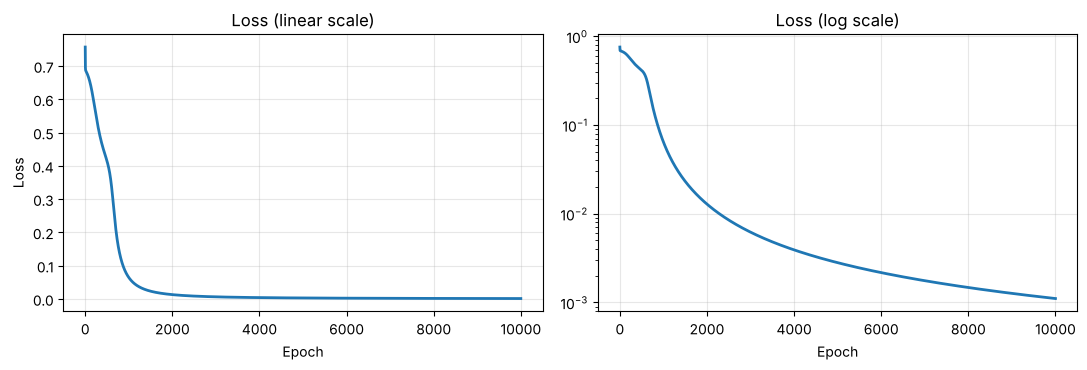

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
axes[0].plot(net.loss_history, linewidth=2)
axes[0].set_title("Loss (linear scale)"); axes[0].set_xlabel("Epoch"); axes[0].set_ylabel("Loss")
axes[1].plot(net.loss_history, linewidth=2)
axes[1].set_yscale("log"); axes[1].set_title("Loss (log scale)"); axes[1].set_xlabel("Epoch")
for ax in axes:
    ax.grid(alpha=0.3)
plt.tight_layout(); plt.show()

### What the network learned: the decision boundary

Colours show the network's answer for **every** point of the input square, not just the four training points. The black line is where the probability is exactly 0.5. Circles should be 0 and squares 1. For XOR the boundary has to bend, because no straight line separates the two diagonals.

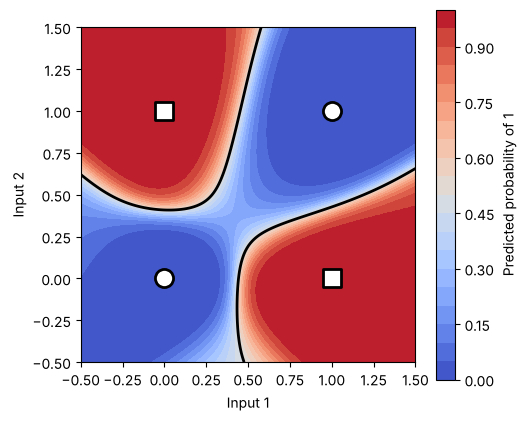

In [6]:
xx, yy, grid = plots.probability_grid(net, resolution=200)
fig, ax = plt.subplots(figsize=(5.4, 4.8))
filled = ax.contourf(xx, yy, grid, levels=np.linspace(0, 1, 21), cmap="coolwarm", vmin=0, vmax=1)
ax.contour(xx, yy, grid, levels=[0.5], colors="black", linewidths=2)
for (a, b), target in zip(X, y.ravel()):
    ax.scatter(a, b, s=170, marker="s" if target else "o", facecolor="white",
               edgecolor="black", linewidth=2, zorder=3)
ax.set_xlabel("Input 1"); ax.set_ylabel("Input 2"); ax.set_aspect("equal")
fig.colorbar(filled, ax=ax, label="Predicted probability of 1")
plt.show()

### What the hidden neurons do

Each column is a hidden neuron, each row an input. Every neuron responds to a *different pattern* of inputs, and the output neuron combines those patterns into the answer. This is the "learned representation" that makes XOR possible.

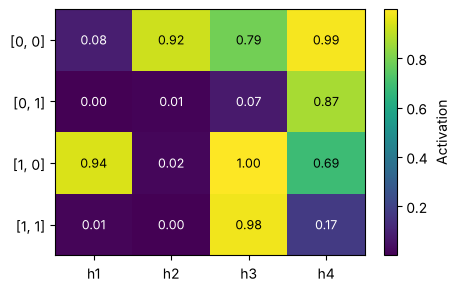

In [7]:
hidden = net.forward(X)[1]                      # outputs of the hidden layer
fig, ax = plt.subplots(figsize=(5, 3.2))
image = ax.imshow(hidden, cmap="viridis", aspect="auto")
ax.set_xticks(range(hidden.shape[1]), [f"h{i + 1}" for i in range(hidden.shape[1])])
ax.set_yticks(range(4), [str(r.astype(int).tolist()) for r in X])
for r in range(hidden.shape[0]):
    for c in range(hidden.shape[1]):
        ax.text(c, r, f"{hidden[r, c]:.2f}", ha="center", va="center",
                color="black" if hidden[r, c] > 0.5 else "white", fontsize=9)
fig.colorbar(image, ax=ax, label="Activation"); plt.show()

## 3. One training step, by hand

`explain_training_step` prints every number involved in one step on a single example: the weighted sums `Z`, the activations `A`, the loss, the error flowing backwards (`dZ`), the gradients (`dW`, `db`) and the weights before and after the update. It uses a **fresh, untrained** network so the error is large and easy to see. It also checks its own gradients against the real `backward()` method.

In [8]:
fresh = NeuralNetwork(layer_sizes=(2, 4, 1), learning_rate=0.5, seed=42)
print(explain_training_step(fresh, X, y, example_index=3))     # example 3 is the input [1, 1]

STEP-BY-STEP: ONE TRAINING STEP
Network : 2 -> 4 -> 1 | hidden activation: sigmoid, output: sigmoid | 17 parameters
Example : input [1.0000 1.0000] | expected output [0.0000]
(Using the network's CURRENT weights. Only one example is used, so m = 1.)

1) FORWARD PROPAGATION   Z = A_previous @ W + b,   A = activation(Z)
----------------------------------------------------------------------
Layer 1 (hidden, sigmoid)
  W (2, 4):
    [[ 0.3047 -1.0400  0.7505  0.9406]
     [-1.9510 -1.3022  0.1278 -0.3162]]
  b (1, 4): [[0.0000 0.0000 0.0000 0.0000]]
  Z = [[-1.6463 -2.3422  0.8783  0.6243]]
  A = [[0.1616 0.0877 0.7065 0.6512]]

Layer 2 (output, sigmoid)
  W (4, 1):
    [[-0.0168]
     [-0.8530]
     [ 0.8794]
     [ 0.7778]]
  b (1, 1): [[0.0000]]
  Z = [[1.0502]]
  A = [[0.7408]]

2) LOSS   L = -( y*log(p) + (1-y)*log(1-p) )
----------------------------------------------------------------------
  prediction p = [[0.7408]]   expected y = [[0.0000]]
  loss = 1.350241   (0 would be perfect;

## 4. Proving backpropagation is correct

Backpropagation computes gradients with calculus. A completely independent way to get the same numbers is to *measure* them: nudge one parameter up and down by a tiny amount and see how the loss changes. If the two agree to many decimals, the backpropagation code is right.

In [9]:
text, ok = format_gradient_check(gradient_check(fresh, X, y))
print(text)
assert ok

GRADIENT CHECK: backpropagation vs numerically measured gradients
parameter         shape         max abs error   max rel error  result
------------------------------------------------------------------
weights layer 1   (2, 4)             1.22e-10        1.16e-06  PASS
weights layer 2   (4, 1)             1.40e-10        1.48e-09  PASS
biases layer 1    (1, 4)             1.78e-10        2.18e-07  PASS
biases layer 2    (1, 1)             9.76e-11        6.46e-10  PASS
------------------------------------------------------------------
Result: every gradient matches, so backpropagation is correct.


## 5. Activation functions

The activation decides how each neuron reshapes its weighted sum. Same network, same seed, only the hidden activation changes. (This is one run with one seed, so treat it as an illustration: other seeds can rank them differently, and ReLU can fail with only 4 neurons because a neuron can get stuck at 0 permanently.)

In [10]:
print(f"{'activation':<12}{'epochs to loss<0.1':>20}{'final loss':>14}{'accuracy':>11}")
for activation in ["sigmoid", "tanh", "relu", "leaky_relu"]:
    model = NeuralNetwork((2, 4, 1), hidden_activation=activation, learning_rate=0.5, seed=42)
    model.train(X, y, epochs=3000, verbose=False)
    loss, accuracy = model.evaluate(X, y)
    first = epochs_to_threshold(model.loss_history)
    print(f"{activation:<12}{str(first) if first else 'never':>20}{loss:>14.6f}{accuracy * 100:>10.0f}%")

activation    epochs to loss<0.1    final loss   accuracy


sigmoid                      868      0.006200       100%


tanh                         205      0.001518       100%


relu                         112      0.000997       100%


leaky_relu                   120      0.001036       100%


## 6. Optimizers

The optimizer decides *how* the gradient is turned into a step. Plain gradient descent just walks downhill; momentum remembers its direction; RMSprop and Adam adapt the step size per weight. Adam and RMSprop need a much smaller learning rate than gradient descent, so each gets its usual one.

optimizer  learning rate  epochs to loss<0.1    final loss


gd                   0.5                 868      0.006203


momentum             0.5                 127      0.000531


rmsprop             0.01                 364      0.000000


adam                0.01                 407      0.001255


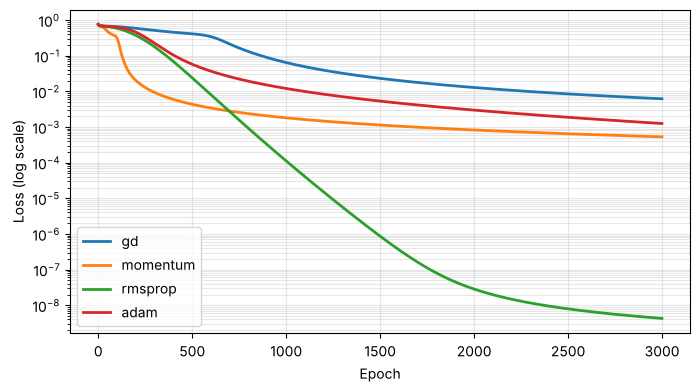

In [11]:
fig, ax = plt.subplots(figsize=(8, 4.2))
print(f"{'optimizer':<10}{'learning rate':>14}{'epochs to loss<0.1':>20}{'final loss':>14}")
for optimizer in ["gd", "momentum", "rmsprop", "adam"]:
    model = NeuralNetwork((2, 4, 1), learning_rate=OPTIMIZER_LR[optimizer], optimizer=optimizer, seed=42)
    model.train(X, y, epochs=3000, verbose=False)
    first = epochs_to_threshold(model.loss_history)
    print(f"{optimizer:<10}{OPTIMIZER_LR[optimizer]:>14}{str(first) if first else 'never':>20}"
          f"{model.loss_history[-1]:>14.6f}")
    ax.plot(model.loss_history, linewidth=2, label=optimizer)
ax.set_yscale("log"); ax.set_xlabel("Epoch"); ax.set_ylabel("Loss (log scale)")
ax.grid(alpha=0.3, which="both"); ax.legend(); plt.show()

## 7. Real data: Iris flowers

So far the whole dataset was four rows, so there was nothing left over to test on. Real work needs three separate parts:

* **training** rows: the network learns from these;
* **validation** rows: used to watch progress and decide when to stop (never learned from);
* **test** rows: touched only once, at the end, to get an honest score.

`load_dataset("iris")` reads 150 real flower measurements bundled in the `data/` folder. `run_experiment` splits the rows (stratified, so every species appears in each part), standardizes the inputs using only the training rows, trains a **softmax** network (one output per species, probabilities summing to 1) with early stopping, and measures all three parts.

In [12]:
iris = load_dataset("iris")
print(iris.description)
print("rows:", iris.X.shape[0], "| inputs:", iris.input_size, "| classes:", iris.class_names)
print("rows per class:", np.bincount(iris.y))
print("first flower (sepal length, sepal width, petal length, petal width in cm):", iris.X[0])

150 real iris flowers: 4 measurements -> species (3 classes)
rows: 150 | inputs: 4 | classes: ('setosa', 'versicolor', 'virginica')
rows per class: [50 50 50]
first flower (sepal length, sepal width, petal length, petal width in cm): [5.1 3.5 1.4 0.2]


In [13]:
result = run_experiment(iris, verbose=True, print_every=60)
net_iris, split = result.network, result.split
print()
print(net_iris.summary())
print(f"rows: {len(split.X_train)} train / {len(split.X_val)} validation / {len(split.X_test)} test")
print(f"stopped early at epoch {net_iris.epochs_run}; restored weights from epoch {net_iris.best_epoch}")
for part in ("train", "val", "test"):
    print(f"{part:>5}: loss {result.metrics[part + '_loss']:.4f} | accuracy {result.metrics[part + '_accuracy'] * 100:.1f}%")

Epoch     60 | Loss: 0.235288 | Val loss: 0.287709 | Val acc: 83.3%
Epoch    120 | Loss: 0.084374 | Val loss: 0.129608 | Val acc: 93.3%
Epoch    180 | Loss: 0.051788 | Val loss: 0.125875 | Val acc: 93.3%
Early stopping at epoch 187: validation loss did not improve by 1e-06 for 40 epochs.

4 -> 8 -> 3 | hidden activation: tanh, output: softmax | 67 parameters
rows: 90 train / 30 validation / 30 test
stopped early at epoch 187; restored weights from epoch 147
train: loss 0.0643 | accuracy 98.9%
  val: loss 0.1213 | accuracy 93.3%
 test: loss 0.0762 | accuracy 100.0%


The **confusion matrix** counts, for each true species (rows), what the network predicted (columns). A perfect model puts everything on the diagonal. Note how small the test set is (30 flowers): one wrong flower moves accuracy by 3.3 points, so a single split can look better or worse than the model really is.

rows = true class, columns = predicted class
[[10  0  0]
 [ 0 10  0]
 [ 0  0 10]]
classes: {0: 'setosa', 1: 'versicolor', 2: 'virginica'}


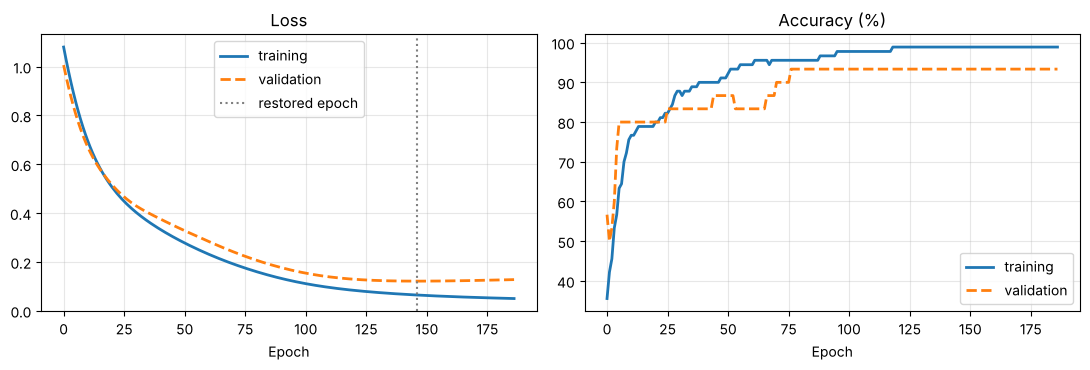

In [14]:
matrix = net_iris.confusion_matrix(split.X_test, split.y_test)
print("rows = true class, columns = predicted class")
print(matrix)
print("classes:", dict(enumerate(iris.class_names)))

fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
history = net_iris.history
axes[0].plot(history["loss"], label="training", linewidth=2)
axes[0].plot(history["val_loss"], label="validation", linewidth=2, linestyle="--")
axes[0].axvline(net_iris.best_epoch - 1, color="grey", linestyle=":", label="restored epoch")
axes[0].set_title("Loss"); axes[0].set_xlabel("Epoch"); axes[0].legend(); axes[0].grid(alpha=0.3)
axes[1].plot(np.array(history["accuracy"]) * 100, label="training", linewidth=2)
axes[1].plot(np.array(history["val_accuracy"]) * 100, label="validation", linewidth=2, linestyle="--")
axes[1].set_title("Accuracy (%)"); axes[1].set_xlabel("Epoch"); axes[1].legend(); axes[1].grid(alpha=0.3)
plt.tight_layout(); plt.show()

When the validation loss stops improving while the training loss keeps falling, the network has started to *memorise* the training rows instead of learning the pattern (**overfitting**). Early stopping with best-weight restore keeps the weights from the best validation epoch.

Because one split is a small, lucky-or-unlucky sample, it is more honest to repeat the experiment with different seeds (each seed also changes the split):

In [15]:
scores = []
for seed in range(42, 62):
    outcome = run_experiment(iris, {"seed": seed})
    scores.append(outcome.metrics["test_accuracy"])
scores = np.array(scores)
print(f"20 runs, test accuracy: mean {scores.mean() * 100:.1f}% | std {scores.std() * 100:.1f} | "
      f"min {scores.min() * 100:.1f}% | max {scores.max() * 100:.1f}%")

20 runs, test accuracy: mean 96.3% | std 2.8 | min 90.0% | max 100.0%


## 8. Real data: handwritten digits

1,797 real scans of handwritten digits, each an 8×8 grid of pixel intensities (64 inputs), 10 classes. The network is 64 → 64 → 10 with ReLU hidden neurons, softmax output, the Adam optimizer, mini-batches of 32 and early stopping, all chosen as this dataset's recommended settings.

In [16]:
digits = load_dataset("digits8x8")
print(digits.description)
outcome = run_experiment(digits, verbose=True, print_every=10)
net_digits, split_d = outcome.network, outcome.split
print()
print(net_digits.summary())
print(f"rows: {len(split_d.X_train)} train / {len(split_d.X_val)} validation / {len(split_d.X_test)} test")
for part in ("train", "val", "test"):
    print(f"{part:>5}: loss {outcome.metrics[part + '_loss']:.4f} | accuracy {outcome.metrics[part + '_accuracy'] * 100:.1f}%")

1,797 real handwritten digits as 8x8 pixel pictures (10 classes)
Epoch     10 | Loss: 0.031502 | Val loss: 0.106228 | Val acc: 96.4%


Epoch     20 | Loss: 0.007799 | Val loss: 0.095022 | Val acc: 97.5%
Early stopping at epoch 29: validation loss did not improve by 1e-06 for 10 epochs.

64 -> 64 -> 10 | hidden activation: relu, output: softmax | 4810 parameters
rows: 1079 train / 359 validation / 359 test
train: loss 0.0080 | accuracy 100.0%
  val: loss 0.0788 | accuracy 97.8%
 test: loss 0.1067 | accuracy 96.7%


Below: test images the network has **never seen**. Mistakes come first (red, "predicted (is true)"), then some correct answers (green). Many of the mistakes are digits that are genuinely ambiguous at 8×8 resolution.

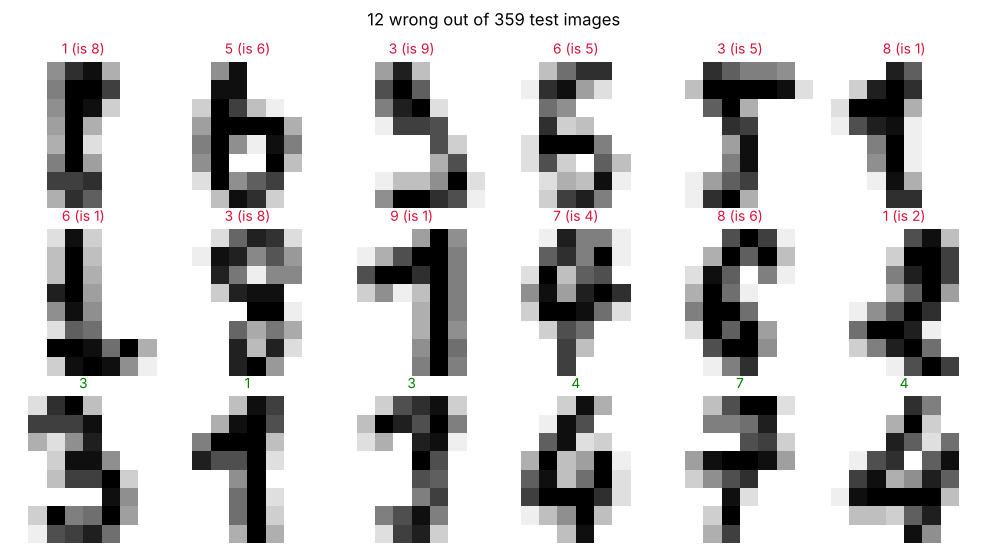

In [17]:
Xt, yt = split_d.X_test, split_d.y_test
predicted = net_digits.predict(Xt)
wrong = np.flatnonzero(predicted != yt)
right = np.flatnonzero(predicted == yt)
shown = np.concatenate([wrong, right])[:18]

fig, axes = plt.subplots(3, 6, figsize=(10, 5.6))
for ax, index in zip(axes.ravel(), shown):
    ax.imshow(Xt[index].reshape(8, 8), cmap="gray_r", interpolation="nearest")
    ok = predicted[index] == yt[index]
    ax.set_title(str(predicted[index]) if ok else f"{predicted[index]} (is {yt[index]})",
                 color="green" if ok else "crimson", fontsize=10)
    ax.axis("off")
fig.suptitle(f"{len(wrong)} wrong out of {len(yt)} test images")
plt.tight_layout(); plt.show()

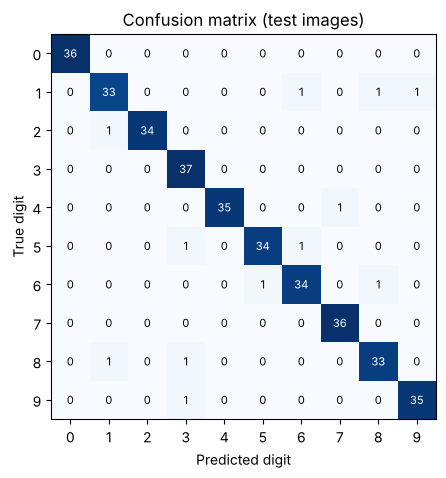

In [18]:
matrix = net_digits.confusion_matrix(Xt, yt)
fig, ax = plt.subplots(figsize=(5.6, 5))
ax.imshow(matrix / matrix.sum(axis=1, keepdims=True), cmap="Blues", vmin=0, vmax=1)
for r in range(10):
    for c in range(10):
        ax.text(c, r, matrix[r, c], ha="center", va="center", fontsize=8,
                color="white" if matrix[r, c] > 0.5 * matrix[r].sum() else "black")
ax.set_xticks(range(10)); ax.set_yticks(range(10))
ax.set_xlabel("Predicted digit"); ax.set_ylabel("True digit"); ax.set_title("Confusion matrix (test images)")
plt.show()

## 9. Saving and loading a trained model

`save` stores the weights and settings in a single `.npz` file (plain arrays only, no pickled code), and `load` rebuilds an identical network.

In [19]:
import tempfile

with tempfile.TemporaryDirectory() as folder:
    path = net_digits.save(os.path.join(folder, "digits_model"))
    print("saved to a file of", os.path.getsize(path), "bytes")
    reloaded = NeuralNetwork.load(path)

same = np.array_equal(net_digits.predict_proba(Xt), reloaded.predict_proba(Xt))
print("reloaded network gives identical probabilities:", same)
assert same

saved to a file of 43380 bytes
reloaded network gives identical probabilities: True


## 10. Things to try

* In section 2, change `learning_rate` to `0.05` and to `5.0`. What happens to the loss curve?
* Set the hidden layer to **1** neuron `(2, 1, 1)`. Why can't it solve XOR?
* In section 5, try `hidden=(2, 8, 1)` with ReLU. Does widening the layer fix a stuck network?
* In section 7, change the seed in `run_experiment(iris, {"seed": 7})`. Does the test accuracy change? Why?
* In section 8, call `run_experiment(digits, {"hidden": [8]})` and then `{"l2": 0.01}`, and compare train and test accuracy.
* Read `neural_network.py`: `forward`, `backward` and `update_parameters` are the whole learning algorithm.